# In-Context Learning, Part 1b: What Does Claude Learn From Your Examples?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/in-context-learning/02_icl_in_claude.ipynb)

In Part 1a a tiny transformer learned to do regression from the examples in its prompt. Large language models do the same thing at scale: put a few examples in a prompt and the model picks up the pattern. But *what* does it pick up? The input–output mapping you showed it, or what it already believed? And does the mix of examples quietly bias its answers?

We test three things with Claude, using simple, controlled experiments:

1. **Regression from examples:** can it infer a new linear function from (x, y) pairs, and how close does it get to least squares?
2. **Whose rules win:** if the examples' labels are flipped or replaced by nonsense words, does it follow the examples or its prior knowledge?
3. **Hidden bias:** when most examples carry one label, do *ambiguous* inputs drift toward it?

**Runtime:** seconds. The notebook replays recorded answers, so **no API key is needed and nothing is spent**. A live mode at the end uses your own key; re-running every experiment costs about $0.40.

> 🎬 *Video walkthrough: coming soon.*

## 0. Setup

In [1]:
import os, sys, json
if "google.colab" in sys.modules and not os.path.exists("icl_llm"):
    !git clone -q --depth 1 https://github.com/nathanmaulding/tutorial-projects.git
    %cd tutorial-projects/in-context-learning
    !pip install -q anthropic

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from icl_llm import analysis as A
from icl_llm.claude import ask, spent
from icl_llm.experiments import regression_task, label_prompt, POSITIVE, NEGATIVE, NEUTRAL

plt.rcParams.update({"figure.figsize": (7.5, 4.3), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
pd.set_option("display.precision", 2)
print(f"recorded API spend for every experiment in this notebook: ${spent():.2f}")

recorded API spend for every experiment in this notebook: $0.40


## 1. Measuring in-context learning fairly

Two design choices matter more than they look:

- **Thinking off.** Claude 5 models think step by step by default. That's great for answers, but here we want to measure what the model infers *in one pass* from the examples, not what it can work out with a scratchpad. We switch thinking off (`thinking={"type": "disabled"}` for Haiku, `{"type": "between_tools"}` for Sonnet). Opus 5.5 doesn't allow it to be switched off, so it isn't used here.
- **A clean answer format.** Asked for "the number only", models sometimes start working out loud anyway ("Looking at the data: x = -5.53…"). A careless parser then grabs *x* as the answer. That happened in a first version of this notebook and made the larger model look terrible. The fix is **structured output**: the reply is constrained to `{"y": <number>}`.

Here is one regression prompt, exactly as sent, and Haiku's recorded answer:

In [2]:
prompt, x, y, truth = regression_task(k=4, trial=0)
print(prompt)
print("\nHaiku's answer:", ask(prompt, model="claude-haiku-5-5", max_tokens=30, json_number=True), f"   (true value {truth:.2f})")

Here are input/output pairs from an unknown process:
x = -5.53, y = 10.03
x = 5.06, y = 7.11
x = -5.79, y = 9.08
x = -4.27, y = 9.39
x = 8.22, y = ?

Give your best guess for y, even if you are unsure.

Haiku's answer: {"y": 6.9}    (true value 5.92)


## 2. Experiment 1: regression from examples

For each prompt we draw a new line $y = w x + b$ plus a little noise, show $k$ points, and ask for $y$ at a new $x$. We compare the model with **least squares** (the right algorithm), **nearest neighbour** (copy the closest example) and **the mean of the y's**.

> ⏸️ **Pause and predict:** at $k = 1$, least squares has nothing to fit and just guesses the one $y$ it saw. Will Claude do better or worse than that? And how close to least squares will it get at $k = 32$?

In [3]:
reg = A.regression()
reg

,model,k,trials,answered,model error,95% interval,least squares,nearest neighbour,mean of the y's
0,Haiku 5.5,1,25,1.0,6.15,"(4.21, 9.34)",8.21,8.21,8.21
1,Haiku 5.5,2,25,1.0,1.84,"(1.29, 2.62)",0.60,2.84,8.61
2,Haiku 5.5,4,25,1.0,1.01,"(0.48, 2.06)",0.25,2.53,7.36
3,Haiku 5.5,8,25,1.0,0.58,"(0.26, 1.17)",0.14,0.73,9.27
4,Haiku 5.5,16,25,1.0,0.37,"(0.31, 0.45)",0.14,0.41,4.22
5,Haiku 5.5,32,25,1.0,0.32,"(0.22, 0.46)",0.08,0.52,4.43
6,Sonnet 5.5,1,15,1.0,5.44,"(1.25, 10.69)",8.21,8.21,8.21
7,Sonnet 5.5,2,15,1.0,1.85,"(0.8, 2.83)",0.75,2.84,7.47
8,Sonnet 5.5,4,15,1.0,1.49,"(0.73, 2.82)",0.26,3.02,4.51
9,Sonnet 5.5,8,15,1.0,0.23,"(0.15, 0.7)",0.11,0.73,9.15


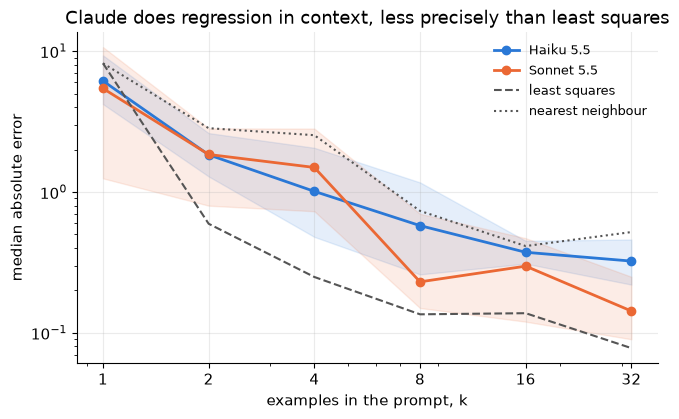

In [4]:
fig, ax = plt.subplots()
for (model, g), c in zip(reg.groupby("model"), SERIES):
    lo = [i[0] for i in g["95% interval"]]; hi = [i[1] for i in g["95% interval"]]
    ax.plot(g.k, g["model error"], "-o", color=c, lw=2, label=model)
    ax.fill_between(g.k, lo, hi, color=c, alpha=0.12)
ref = reg[reg.model == "Haiku 5.5"]
ax.plot(ref.k, ref["least squares"], "--", color="#555", label="least squares")
ax.plot(ref.k, ref["nearest neighbour"], ":", color="#555", label="nearest neighbour")
ax.set(xscale="log", yscale="log", xlabel="examples in the prompt, k", ylabel="median absolute error",
       title="Claude does regression in context, less precisely than least squares")
ax.set_xticks([1, 2, 4, 8, 16, 32], ["1", "2", "4", "8", "16", "32"])
ax.legend(frameon=False, fontsize=9); plt.show()

**What just happened.**
- **It really learns the line from the examples.** Error falls steadily as examples are added, and it's far better than averaging the y's at every $k \ge 2$. Against copying the nearest point it's usually better, but not always: at $k = 16$ Haiku is no better than nearest neighbour (0.37 vs 0.41), and at $k = 4$ Sonnet's interval overlaps it. Qualitatively it's the same behaviour as the tiny transformer in Part 1a, done far less precisely.
- **It isn't least squares.** Even at $k = 32$ its error is 2–4 times that of least squares. A language model reads numbers as text and has no exact arithmetic in a single pass. This is the reason to give an agent a fitting *tool* rather than ask it to eyeball parameters (Part 1 of the agentic-AI tutorial found the same).
- **At $k = 1$ it beats least squares.** With one point, least squares can only echo the $y$ it saw. Claude's guess is better because it brings a prior about what "an unknown process" usually looks like. In-context learning combines the examples with what the model already believes, and that is the theme of the next experiment.

The samples are small (25 prompts per point for Haiku, 15 for Sonnet), so read the shaded intervals before comparing the two models.

## 3. Experiment 2: whose rules win, the examples' or the model's?

Sixteen labelled movie, product and restaurant reviews, then a new review to label. Three versions of the *same* examples:

| condition | positive reviews labelled | negative reviews labelled |
|---|---|---|
| correct | positive | negative |
| **flipped** | negative | positive |
| **meaningless** | foo | bar |

With **flipped** labels the examples teach a rule that contradicts everything the model knows about the word "positive". Does it follow the examples or its prior? This is the experiment of Wei et al. (2023), "Larger language models do in-context learning differently".

In [5]:
from icl_llm.experiments import LABELSETS
demo = [(POSITIVE[0], 0), (NEGATIVE[0], 1), (POSITIVE[1], 0)]
print(label_prompt(demo, NEGATIVE[5], LABELSETS["flipped"])[:600])

Review: The soundtrack gave me chills and the ending was perfect.
Label: negative

Review: The plot made no sense and I nearly walked out.
Label: positive

Review: I laughed from the first scene to the last.
Label: negative

Review: The room smelled of smoke and the bed was broken.
Label:

Reply with the label only, using one of the labels shown above.


> ⏸️ **Pause and predict:** which model do you expect to follow the flipped labels more often, the smaller (Haiku) or the larger (Sonnet)?

In [6]:
lab = A.labels()
lab

,model,labels in the examples,queries,follows the examples,95% interval,answers with the real sentiment word
0,Haiku 5.5,correct,24,1.00,"(0.86, 1.0)",1.00
1,Haiku 5.5,flipped,24,0.79,"(0.6, 0.91)",0.21
2,Haiku 5.5,meaningless,24,1.00,"(0.86, 1.0)",0.00
3,Sonnet 5.5,correct,24,1.00,"(0.86, 1.0)",1.00
4,Sonnet 5.5,flipped,24,1.00,"(0.86, 1.0)",0.00
5,Sonnet 5.5,meaningless,24,1.00,"(0.86, 1.0)",0.00


**What just happened.**
- **Both models learn meaningless labels perfectly.** "foo" for positive and "bar" for negative is learned from 16 examples every time. The mapping is being read from the prompt, not recalled.
- **With flipped labels the larger model follows the examples more.** Sonnet follows the flipped rule in all 24 queries. Haiku does in 79% and reverts to the real sentiment word in the other 21%. That matches what Wei et al. found: larger models are more willing to override their prior knowledge when the examples demand it.
- **Why it matters for science:** if you use few-shot prompts to label data, say classifying assay outcomes or adverse events, the model blends your examples with its prior. When your labelling convention disagrees with common usage, a smaller model may quietly revert to common usage.

## 4. Experiment 3: do the examples bias ambiguous inputs?

Now the examples are skewed: 14 positive and 2 negative, balanced 8:8, or 2 positive and 14 negative. The queries are **neutral** reviews ("The tour lasted two hours."), so any lean comes from the examples, not the input. Earlier language models showed strong **majority-label bias** (Zhao et al. 2021, "Calibrate before use").

In [7]:
imb = A.imbalance()
imb

,model,examples,neutral queries,answered with a label,share called positive (of those labelled),95% interval,other answers
0,Haiku 5.5,14 positive : 2 negative,48,0.38,0.67,"(0.44, 0.84)","ambigu, i finished, mixed, neutral, the review..."
1,Haiku 5.5,balanced 8 : 8,48,0.44,0.29,"(0.14, 0.5)","ambigu, i can't de, i'm not s, it's ambi, mixe..."
2,Haiku 5.5,2 positive : 14 negative,48,0.38,0.33,"(0.16, 0.56)","i can't te, it's uncle, mixed, neutral, this o..."
3,Sonnet 5.5,14 positive : 2 negative,48,0.96,0.22,"(0.12, 0.36)",neutral
4,Sonnet 5.5,balanced 8 : 8,48,1.00,0.10,"(0.05, 0.22)",
5,Sonnet 5.5,2 positive : 14 negative,48,1.00,0.10,"(0.05, 0.22)",


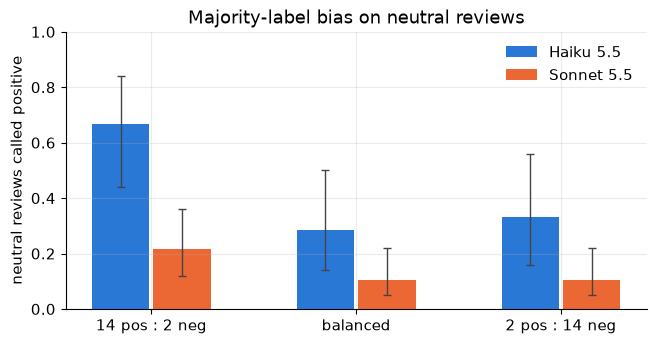

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for j, ((model, g), c) in enumerate(zip(imb.groupby("model", sort=False), SERIES)):
    xs = np.arange(len(g)) + (j - 0.5) * 0.3
    v = g["share called positive (of those labelled)"].to_numpy()
    lo = np.array([i[0] for i in g["95% interval"]]); hi = np.array([i[1] for i in g["95% interval"]])
    ax.bar(xs, v, 0.28, color=c, label=model)
    ax.errorbar(xs, v, yerr=[np.clip(v - lo, 0, None), np.clip(hi - v, 0, None)], fmt="none", color="#444", capsize=3, lw=1)
ax.set_xticks(range(3), ["14 pos : 2 neg", "balanced", "2 pos : 14 neg"])
ax.set(ylabel="neutral reviews called positive", ylim=(0, 1), title="Majority-label bias on neutral reviews")
ax.legend(frameon=False); plt.show()

**What just happened.**
- **Haiku shows majority-label bias.** Neutral reviews are called positive 67% of the time when the examples lean positive, against about 30% otherwise. Haiku also often refuses to choose, answering "neutral" or "mixed" in more than half the cases even though only two labels were offered. Shares above are among the answers that used a label.
- **Sonnet is much less swayed by the skew** (22% vs 10%), but it has its own lean: it calls about 90% of neutral reviews "negative". That's a bias from its prior, not from the examples.
- **The lesson:** the *composition* of your examples is a hidden parameter. Balance the labels, check how the model treats ambiguous cases, and never read a few-shot classifier's error rate off clear-cut examples alone.

## 5. Run it live (optional, uses your own key)

Every answer above came from the replay cache. To re-run with your own key, set `RUN_LIVE = True`. Answers already cached are replayed for free; new ones are added. A spending cap (`ICL_TOTAL_CAP`, default $5) is checked before every call. Use a separate API key with a monthly spending limit.

In [9]:
RUN_LIVE = False

if RUN_LIVE:
    if "google.colab" in sys.modules and not os.environ.get("ANTHROPIC_API_KEY"):
        from google.colab import userdata
        os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
    from icl_llm import experiments as X
    X.regression(model="claude-haiku-5-5", ks=(1, 2, 4, 8, 16, 32, 64), trials=10)   # adds k = 64
    print(A.regression().query("model == 'Haiku 5.5'"))
else:
    print("Replay mode: set RUN_LIVE = True to call the API with your own key.")

Replay mode: set RUN_LIVE = True to call the API with your own key.


## Recap

| Question | Finding |
|---|---|
| Does Claude learn a new function from examples? | Yes: error falls steadily with more examples, far below averaging and usually below copying the nearest point, but 2–4x worse than least squares |
| Does it bring its own prior? | Yes: with 1 example it beats least squares by guessing sensibly |
| Examples vs prior knowledge | Both models learn arbitrary labels; with flipped labels Sonnet always follows the examples, Haiku reverts 21% of the time |
| Hidden bias from example mix | Haiku leans toward the majority label on neutral inputs; Sonnet barely, but leans negative on neutral text |

**The thread through Parts 1a and 1b:** in-context learning is a learning algorithm built by pretraining. It's real, and it's shaped by the data the model was trained on. That's exactly the question for Part 2: what happens when the pretrained in-context learner is a model built for *scientific tables*, pointed at real cancer data?

## Try it yourself

1. Re-run Experiment 2 with 4 and 32 examples instead of 16. Does Haiku follow flipped labels more as the evidence grows?
2. Make the regression harder: a quadratic $y = a x^2 + b$. Does Claude still improve with more examples?
3. Calibrate Haiku's majority bias away: add a "content-free" query ("N/A") to measure its baseline lean, then correct for it (Zhao et al. 2021).